# 05 — Recommendations: what CS, Sales, Product and Marketing should do, and what it is worth

**Revenue Analytics · data as of 30 Sep 2026 · synthetic data** (see `docs/data_model.md`)
Request: *"Which accounts should the CS team prioritise?"* plus the follow-up every VP asks: *"and what is it worth?"*
(`docs/01_request_and_scope.md`, question Q6)

In [1]:
import pandas as pd
from saas_rev import marts
from saas_rev.nbutil import md, setup, show
from saas_rev.analysis import recommendations as R
from saas_rev.theme import money, pct
setup()
rates = R.loss_rates()
plays = R.build_plays()
t = R.plays_table(plays)
base = R.forward_base_mrr()
k_sc, k_ex, k_tr, k_m = (marts.read_key_numbers(x) for x in ("silent_churn", "expansion", "transitions", "metrics"))
top = t.sort_values("nrr_pts", ascending=False)

## TL;DR

In [2]:
md(f"""
- **Seven plays, each with an owner, a target list that exists today, a holdout and a stated risk.** Together they are worth about
  **+{t['nrr_pts'].sum() * 100:.1f} NRR points next year** (range +{t['nrr_pts_low'].sum() * 100:.1f} to +{t['nrr_pts_high'].sum() * 100:.1f}),
  ≈ {money(t['impact_mrr'].sum() * 12)} of ARR kept or added, against a 12-month NRR of {pct(k_m['nrr_ttm'])} today and a Q3 run-rate of {pct(k_m['nrr_runrate_q3_2026'])}.
- **Biggest levers:** {top.iloc[0]['id']} {top.iloc[0]['play'].lower()} (+{top.iloc[0]['nrr_pts'] * 100:.2f} pts) and {top.iloc[1]['id']} {top.iloc[1]['play'].lower()}
  (+{top.iloc[1]['nrr_pts'] * 100:.2f} pts). Upgrade outreach (P4) is real but small: Basic → Premium upgrades are about $200 MRR each.
- **What is measured and what is assumed.** The target lists, their MRR and how much MRR such accounts lost historically are measured.
  The effect of each play is an assumption (low / base / high) — no play has been run yet — so every play ships with a holdout that
  replaces the assumption with a measured effect within one or two quarters.
- **No double counting:** each account sits in exactly one play; plays aimed at new signups are sized only on what reaches existing customers
  within 12 months (new customers are not in next year's NRR base).
""")


- **Seven plays, each with an owner, a target list that exists today, a holdout and a stated risk.** Together they are worth about
  **+1.5 NRR points next year** (range +0.8 to +2.4),
  ≈ $377.2K of ARR kept or added, against a 12-month NRR of 103.5% today and a Q3 run-rate of 92.9%.
- **Biggest levers:** P1 csm renewal desk for the top 120 at-risk accounts (+0.56 pts) and P7 payment-failure recovery (dunning)
  (+0.30 pts). Upgrade outreach (P4) is real but small: Basic → Premium upgrades are about $200 MRR each.
- **What is measured and what is assumed.** The target lists, their MRR and how much MRR such accounts lost historically are measured.
  The effect of each play is an assumption (low / base / high) — no play has been run yet — so every play ships with a holdout that
  replaces the assumption with a measured effect within one or two quarters.
- **No double counting:** each account sits in exactly one play; plays aimed at new signups are sized only on what reaches existing customers
  within 12 months (new customers are not in next year's NRR base).


## Question
Q6 of the scope: *what should each team do, starting next quarter, and what is each action worth in NRR points?* The answer has to be
something a team lead can start on Monday: a list of accounts or a population, an action, an owner, the expected effect with its
assumptions, how we will know if it worked, and what could go wrong.

## Data
| Input | From | Used for |
|---|---|---|
| `silent_churn__watchlist` | `04_silent_churn` | risk list: silent contraction, CS saves, early-warning flags; CSM vs digital queue, priority |
| `expansion__opportunities` | `03_expansion_signals` | upgrade-opportunity list with propensity and reason codes |
| `reports/key_numbers/transitions.json` | `02_plan_transitions` | packaging change: foregone upgrade MRR, retention upside |
| `fct_account_month_features`, `fct_customer_mrr_monthly` (`sql/41`, `sql/20`) | metric layer | historical 12-month MRR loss of comparable accounts; MRR today |
| `rpt_mrr_waterfall_monthly` (`sql/23`), `stg_invoices` (`sql/04`) | metric layer | involuntary churn, dunning recovery |

Next year's NRR base = MRR of every customer paying on 30 Sep 2026.

In [3]:
md(f"NRR base: **{money(base)} MRR** ({money(base * 12)} ARR). One NRR point = {money(base * 0.01)} of MRR kept or added by Sep 2027.")

NRR base: **$2.1M MRR** ($24.8M ARR). One NRR point = $20.6K of MRR kept or added by Sep 2027.

## Method
For each play:

| Part | Measured or assumed | Example (P1) |
|---|---|---|
| Addressable MRR | measured — MRR of the accounts on the play's list today, or the MRR flow it acts on | MRR of the first 120 accounts of the CSM queue |
| Expected outcome | measured — share of that MRR lost (or added) over 12 months by comparable accounts in history | 12-month MRR loss of flagged CSM-covered accounts |
| Effect of the play | **assumption** (low / base / high), set wide on purpose | share of the expected loss a CSM review prevents |
| Reach | default 100% of the list (adjustable) | the CSM desk is already capped at capacity |

`impact (MRR in 12 months) = addressable × outcome × effect × reach`; `NRR points = impact ÷ NRR base`.

**Measured 12-month MRR loss** = 1 − GRR of a group of account-months: what share of their starting MRR was gone 12 months later
(churn = 100% lost, expansion does not offset). History = month-ends Oct 2024 – Sep 2025, so every 12-month window is complete.

**One play per account**, in this order: P1 CSM desk → P3 Technology renewals → P2 digital → P4 upgrade list → P6 Paid Social
cohorts. P5 (packaging) and P7 (dunning) act on flows, not lists.

## Results
### 1. The evidence base: how much MRR comparable accounts lost

In [4]:
rows = [
    ("All paying accounts", "all_paying"),
    ("Not flagged by the utilization rule, CSM-covered", "not_flagged_csm"),
    ("Flagged by the utilization rule, CSM-covered", "early_warning_csm"),
    ("Not flagged, digital coverage", "not_flagged_digital"),
    ("Flagged, digital coverage", "early_warning_digital"),
    ("Silent contraction (already shrunk ≥ 20%)", "silent"),
    ("Saved by CS (asked to cancel, kept smaller)", "saved_re_risk"),
]
ev = pd.DataFrame([(lab, rates[key], rates[f"{key}_n"]) for lab, key in rows], columns=["Group (account-months)", "12-month MRR loss", "n"])
ren = pd.DataFrame([
    ("Technology, Apr–Sep 2026", rates["renewal_loss_tech_apr_sep_2026"], rates["renewal_loss_tech_apr_sep_2026_n"]),
    ("Other industries, Apr–Sep 2026", rates["renewal_loss_non_tech_apr_sep_2026"], rates["renewal_loss_non_tech_apr_sep_2026_n"]),
    ("Technology, Apr–Sep 2025", rates["renewal_loss_tech_apr_sep_2025"], rates["renewal_loss_tech_apr_sep_2025_n"]),
    ("Other industries, Apr–Sep 2025", rates["renewal_loss_non_tech_apr_sep_2025"], rates["renewal_loss_non_tech_apr_sep_2025_n"]),
], columns=["Annual renewals", "MRR lost at renewal", "n"])
display(ev.style.format({"12-month MRR loss": "{:.1%}", "n": "{:,}"}).hide(axis="index"))
display(ren.style.format({"MRR lost at renewal": "{:.1%}", "n": "{:,}"}).hide(axis="index"))

Group (account-months),12-month MRR loss,n
All paying accounts,14.5%,"21,292"
"Not flagged by the utilization rule, CSM-covered",8.0%,"5,150"
"Flagged by the utilization rule, CSM-covered",29.9%,544
"Not flagged, digital coverage",23.8%,"8,433"
"Flagged, digital coverage",50.6%,"1,289"
Silent contraction (already shrunk ≥ 20%),27.3%,609
"Saved by CS (asked to cancel, kept smaller)",23.0%,89


Annual renewals,MRR lost at renewal,n
"Technology, Apr–Sep 2026",18.1%,136
"Other industries, Apr–Sep 2026",12.0%,420
"Technology, Apr–Sep 2025",12.9%,66
"Other industries, Apr–Sep 2025",11.8%,164


In [5]:
md(f"""**Reading.** The utilization rule separates risk well: flagged CSM-covered accounts lost {pct(rates['early_warning_csm'], 0)} of their MRR over the
next year vs {pct(rates['not_flagged_csm'], 0)} for unflagged ones; for digital accounts {pct(rates['early_warning_digital'], 0)} vs {pct(rates['not_flagged_digital'], 0)}.
Silent-contraction accounts lose a further {pct(rates['silent'], 0)} — but `04_silent_churn` shows comparable unflagged accounts churn or shrink again at the
same rate ({pct(k_sc['followup']['silent_loss_6m'], 0)} vs {pct(k_sc['followup']['unflagged_matched_loss_6m'], 0)} within 6 months): their loss is mostly booked
already, so the lists rank by the early-warning flag and the renewal date, not by past contraction. Technology annual renewals since April lost
{pct(rates['renewal_loss_tech_apr_sep_2026'], 0)} of MRR at renewal vs {pct(rates['renewal_loss_non_tech_apr_sep_2026'], 0)} for other industries
(n = {rates['renewal_loss_tech_apr_sep_2026_n']}: a real but noisy gap).""")

**Reading.** The utilization rule separates risk well: flagged CSM-covered accounts lost 30% of their MRR over the
next year vs 8% for unflagged ones; for digital accounts 51% vs 24%.
Silent-contraction accounts lose a further 27% — but `04_silent_churn` shows comparable unflagged accounts churn or shrink again at the
same rate (25% vs 25% within 6 months): their loss is mostly booked
already, so the lists rank by the early-warning flag and the renewal date, not by past contraction. Technology annual renewals since April lost
18% of MRR at renewal vs 12% for other industries
(n = 136: a real but noisy gap).

### 2. The plays

In [6]:
cols = {"id": "Play", "play": "What", "owner": "Owner", "accounts": "Accounts", "addressable_mrr": "Addressable MRR",
        "outcome_rate": "Measured outcome", "effect_low": "Effect low", "effect_base": "Effect base", "effect_high": "Effect high",
        "impact_mrr": "Impact (MRR, 12 m)", "nrr_pts": "NRR pts", "nrr_pts_low": "low", "nrr_pts_high": "high"}
tab = t[list(cols)].rename(columns=cols)
display(tab.style.format({"Accounts": "{:,.0f}", "Addressable MRR": "${:,.0f}", "Measured outcome": "{:.1%}", "Effect low": "{:.0%}",
                          "Effect base": "{:.0%}", "Effect high": "{:.0%}", "Impact (MRR, 12 m)": "${:,.0f}",
                          "NRR pts": lambda v: f"+{v * 100:.2f}", "low": lambda v: f"+{v * 100:.2f}", "high": lambda v: f"+{v * 100:.2f}"})
        .hide(axis="index"))

Play,What,Owner,Accounts,Addressable MRR,Measured outcome,Effect low,Effect base,Effect high,"Impact (MRR, 12 m)",NRR pts,low,high
P1,CSM renewal desk for the top 120 at-risk accounts,Head of CS (named + pooled CSMs),120,"$196,188",29.5%,10%,20%,30%,"$11,578",+0.56,+0.28,+0.84
P2,Digital re-engagement for the rest of the risk list,Lifecycle Marketing + Product,798,"$127,317",36.1%,3%,7%,12%,"$3,219",+0.16,+0.07,+0.27
P3,Technology renewals: flexible seat bands,Sales (renewal AEs) + Customer Success,190,"$132,871",20.3%,10%,20%,35%,"$5,392",+0.26,+0.13,+0.46
P4,Premium trial for the highest-propensity Basic accounts,Sales-assist + Product,100,"$5,856",100.0%,15%,30%,50%,"$1,757",+0.09,+0.04,+0.14
P5,Basic packaging: test a capped version before deciding,Product / Pricing,0,"$6,111",100.0%,20%,40%,60%,"$2,444",+0.12,+0.06,+0.18
P6,Paid Social cohorts: activation and annual offer,Growth Marketing + Lifecycle,312,"$38,231",6.3%,20%,35%,50%,$846,+0.04,+0.02,+0.06
P7,Payment-failure recovery (dunning),Billing Operations / RevOps,0,"$20,650",100.0%,15%,30%,45%,"$6,195",+0.30,+0.15,+0.45


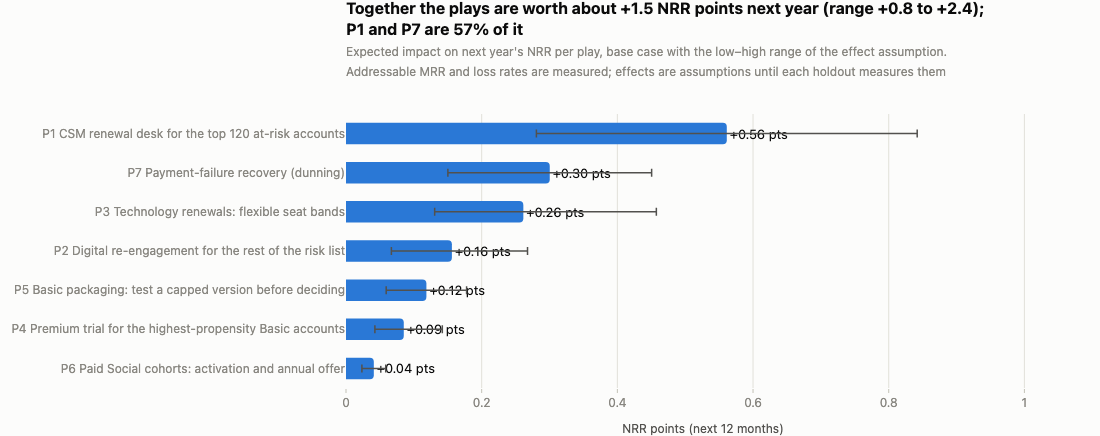

In [7]:
show(R.fig_impact(t))

In [8]:
for p, r in zip(plays, t.itertuples()):
    md(f"""#### {p.id} · {p.title}
**Owner:** {p.owner}
**Who:** {p.who}
**What:** {p.what}
**Evidence:** {p.evidence}
**Expected NRR impact:** +{r.nrr_pts * 100:.2f} pts (range +{r.nrr_pts_low * 100:.2f} to +{r.nrr_pts_high * 100:.2f}) = addressable {money(p.addressable_mrr)} MRR ×
{p.outcome_label} {pct(p.outcome_rate, 1)} × {p.effect_label} {pct(p.effect[1], 0)} (assumption; low {pct(p.effect[0], 0)}, high {pct(p.effect[2], 0)}) × reach {pct(p.reach, 0)}. {p.sizing_note}
**How we will know:** {p.measure}
**Risks:** {p.risk}
""")

#### P1 · CSM renewal desk for the top 120 at-risk accounts
**Owner:** Head of CS (named + pooled CSMs)
**Who:** The first 120 accounts of the CSM queue in docs/account_health_list.csv (CS capacity: 120 reviews a quarter): annual renewals within 120 days first (62 of them), then by ARR at stake; $2.4M ARR
**What:** Usage review 60–90 days before renewal: re-activate idle seats (admin training, re-onboard teams that stopped logging in), agree a right-sized renewal before procurement asks, line up an executive sponsor where the champion left; for Technology accounts a headcount check-in before the next billing date
**Evidence:** CSM-covered accounts the utilization rule flagged lost 30% of their MRR over the next 12 months vs 8% for unflagged CSM-covered accounts (history, Oct 2024 – Sep 2025 month-ends); back-test precision 39% vs a 17% base rate, median lead 4 months. The 324 silently contracting accounts have already lost $649.2K of ARR, but they churn or shrink again no more often than comparable accounts (25% vs 25% within 6 months), so the desk ranks by the early-warning flag and the renewal date
**Expected NRR impact:** +0.56 pts (range +0.28 to +0.84) = addressable $196.2K MRR ×
expected 12-month MRR loss 29.5% × share of the expected loss prevented 20% (assumption; low 10%, high 30%) × reach 100%. Today's top 120 only; later quarters' lists are not counted (conservative).
**How we will know:** Hold out 1 in 5 eligible accounts at random each quarter (business as usual); compare 6- and 12-month GRR (billing-neutral contraction + churn) of worked vs held-out accounts; report monthly to the Head of CS
**Risks:** CSM time (the cap is the constraint); proactive right-sizing lowers MRR now to keep the logo; without the holdout CSMs pick the easy saves and the effect is overstated


#### P2 · Digital re-engagement for the rest of the risk list
**Owner:** Lifecycle Marketing + Product
**Who:** The 798 other accounts on the risk list (digital-coverage accounts and CSM accounts beyond the first 120); $1.5M ARR
**What:** In-app and email nudges to admins ("N seats unused — reassign or invite teammates", automation templates for the account's use case); a pre-renewal email sequence 60 days before annual renewals; seat right-size prompt instead of a silent cut
**Evidence:** Digital-coverage accounts the utilization rule flagged lost 51% of their MRR over the next 12 months vs 24% for unflagged digital accounts (history, n = 1,289 flagged account-months); most are SMB self-serve accounts on monthly billing
**Expected NRR impact:** +0.16 pts (range +0.07 to +0.27) = addressable $127.3K MRR ×
expected 12-month MRR loss 36.1% × share of the expected loss prevented 7% (assumption; low 3%, high 12%) × reach 100%. 
**How we will know:** 50/50 randomised by account; KPI = 90-day and 12-month billing-neutral contraction + churn rate
**Risks:** Email programmes usually move behaviour a little; message fatigue; needs Product time for the in-app prompts


#### P3 · Technology renewals: flexible seat bands
**Owner:** Sales (renewal AEs) + Customer Success
**Who:** The 190 Technology accounts on annual contracts renewing in the next 6 months that are not on the CSM desk ($1.6M ARR)
**What:** Offer a seat band at renewal (commit to about 80% of today's seats, add seats back at the same price during the term) in exchange for renewing annually, instead of waiting for a cut-or-churn decision; route Technology renewals to the renewal desk 90 days out
**Evidence:** Technology annual renewals in Apr–Sep 2026 lost 18% of their MRR at renewal (seat right-sizing + churn, n = 136) vs 12% for other industries in the same months and 13% for Technology a year earlier; Technology expansion fell from 1.5% to 0.3% of starting MRR a quarter (Q3 2025 → Q3 2026) and their 12-month NRR is 95.5%
**Expected NRR impact:** +0.26 pts (range +0.13 to +0.46) = addressable $132.9K MRR ×
expected MRR loss at renewal 20.3% × net share of the renewal loss avoided (after seats given back) 20% (assumption; low 10%, high 35%) × reach 100%. 
**How we will know:** Randomise the offer by renewal month (alternate months) or by account where volume allows; KPI = renewal GRR of offered vs not-offered Technology accounts; report the seats given back separately
**Risks:** The band gives back MRR that some accounts would have kept; if the sector recovers the band looks expensive — limit it to one renewal cycle. Assumes the next 6 months of Technology renewals look like the last 6


#### P4 · Premium trial for the highest-propensity Basic accounts
**Owner:** Sales-assist + Product
**Who:** Each quarter, the top 100 Basic accounts on the upgrade-opportunity list that are not on the risk list (today: 100 accounts, $395.4K ARR)
**What:** Unlock a 14-day Premium trial in-app, with sales-assist outreach for Mid-Market; lead with the behaviour that put the account on the list (Premium paywall hits, automation use, team growth)
**Evidence:** In the time-split back-test the top 100 accounts upgraded at 6.7% within 90 days vs a 2.5% base rate (2.6× lift; test AUC 0.68); a list brings about $1.5K of upgrade MRR a quarter on its own. Basic → Premium upgrades are small (about $200 MRR each), so this is a cheap play, not a big one
**Expected NRR impact:** +0.09 pts (range +0.04 to +0.14) = addressable $5.9K MRR ×
expected 12-month MRR loss 100.0% × relative lift in the upgrade rate 30% (assumption; low 15%, high 50%) × reach 100%. 
**How we will know:** Randomised: 70% of each quarter's list gets the trial + outreach, 30% holdout; KPI = 90-day voluntary upgrade rate and 6-month retention of upgraders (incremental upgrades, not raw upgrades)
**Risks:** Pulling forward upgrades that would have happened anyway (only the holdout shows the increment); discount expectations if Sales leads with price


#### P5 · Basic packaging: test a capped version before deciding
**Owner:** Product / Pricing
**Who:** New Basic signups from Jan 2027 (50/50 test for two quarters); then, if the test wins, every Basic account from Aug 2027
**What:** Keep advanced automations in Basic but cap them (e.g. a monthly run limit), or move analytics dashboards behind the Premium gate; decide at the end of the test on 6-month revenue per new Basic signup
**Evidence:** Since April the voluntary Basic → Premium rate fell from 1.60% to 0.77% a month outside Paid Social; channel mix explains 4% of the fall; part of it was a drift that started before April. The retention upside is not distinguishable from zero, so the change costs about $2.7K MRR a month net (range $475 to $4.8K)
**Expected NRR impact:** +0.12 pts (range +0.06 to +0.18) = addressable $6.1K MRR ×
expected 12-month MRR loss 100.0% × share of the foregone upgrade MRR recovered 40% (assumption; low 20%, high 60%) × reach 100%. Small inside next year's NRR window because the test comes first; once rolled out it is worth about $14.7K of MRR a year at the base effect.
**How we will know:** Decision read in Jul 2027 on the 90-day upgrade rate and early churn of the two arms (≈ 450 signups each); full read on 6-month revenue per new Basic signup (upgrade MRR + retained Basic MRR) in Dec 2027; guardrail: trial → paid conversion of the test cell
**Risks:** Losing the conversion / retention gain that motivated the change; backlash if existing Basic accounts lose a feature — test on new signups first. New signups are not in next year's NRR base, so only the roll-out months count here


#### P6 · Paid Social cohorts: activation and annual offer
**Owner:** Growth Marketing + Lifecycle
**Who:** The 312 paying accounts from the Paid Social program cohorts (first paid Sep 2025 or later; $458.8K ARR) and every new Paid Social signup
**What:** Activation sequence in the first 30 days (first automation, invite teammates), annual-plan offer at day 30, and exclusion of the audiences with the weakest 6-month revenue retention from targeting
**Evidence:** 6-month GRR of Paid Social program cohorts 76% vs 83% for other SMB signups; 12 months after signup 5% had upgraded vs 13%–18% for other channels
**Expected NRR impact:** +0.04 pts (range +0.02 to +0.06) = addressable $38.2K MRR ×
excess 6-month MRR loss vs other SMB signups 6.3% × share of the retention gap to other SMB closed 35% (assumption; low 20%, high 50%) × reach 100%. 
**How we will know:** Alternate signup weeks get the new onboarding (holdout by week); KPI = 6-month revenue retained per $1 of first-month MRR by channel cohort, which Marketing weighs against CAC
**Risks:** Tighter targeting lowers signup volume; the budget trade-off needs CAC (not in this data). Most of the value lands on future cohorts, outside next year's NRR base


#### P7 · Payment-failure recovery (dunning)
**Owner:** Billing Operations / RevOps
**Who:** Monthly card-paying accounts whose renewal charge fails
**What:** Smart retry schedule, automatic card updater, in-app banner and admin email before the 14-day cut-off
**Evidence:** Failed card payments cost $20.6K MRR of churn in the last 12 months (13% of churned MRR); 66% of failed recurring charges are recovered within the dunning window today (invoices, last 12 months)
**Expected NRR impact:** +0.30 pts (range +0.15 to +0.45) = addressable $20.6K MRR ×
expected 12-month MRR loss 100.0% × share of payment-failure churn recovered 30% (assumption; low 15%, high 45%) × reach 100%. 
**How we will know:** A/B test of the retry schedule; KPI = recovery rate within the dunning window
**Risks:** Low; card-network fees for the updater


### 3. How robust is the ranking?
Two stress tests: every effect at its low end, and every list worked at half reach. The ranking is what matters for the decision;
the total is a planning number.

In [9]:
lo = R.plays_table(plays, {p.id: {"effect": p.effect[0]} for p in plays})
half = R.plays_table(plays, {p.id: {"reach": 0.5} for p in plays})
cmp = pd.DataFrame({"Play": t["id"], "Base": t["nrr_pts"] * 100, "All effects low": lo["nrr_pts"] * 100, "Half reach": half["nrr_pts"] * 100})
cmp["Rank (base)"] = cmp["Base"].rank(ascending=False).astype(int)
cmp["Rank (all low)"] = cmp["All effects low"].rank(ascending=False).astype(int)
display(cmp.sort_values("Rank (base)").style.format({"Base": "+{:.2f}", "All effects low": "+{:.2f}", "Half reach": "+{:.2f}"}).hide(axis="index"))
same = (cmp["Rank (base)"] == cmp["Rank (all low)"]).all()
moved = cmp.loc[cmp["Rank (base)"] != cmp["Rank (all low)"], "Play"].tolist()
md(f"Total: base +{t['nrr_pts'].sum() * 100:.2f} pts; all effects at the low end +{lo['nrr_pts'].sum() * 100:.2f}; half reach +{half['nrr_pts'].sum() * 100:.2f}. "
   + ("The order is the same with every effect at its low end, so the ranking rests on the measured addressable MRR and loss rates; "
      "the effect assumptions move the total, not the priorities." if same else
      f"With every effect at its low end only {', '.join(moved)} change places; the top of the ranking rests on the measured "
      "addressable MRR and loss rates, and the effect assumptions mainly move the total."))

Play,Base,All effects low,Half reach,Rank (base),Rank (all low)
P1,+0.56,+0.28,+0.28,1,1
P7,+0.30,+0.15,+0.15,2,2
P3,+0.26,+0.13,+0.13,3,3
P2,+0.16,+0.07,+0.08,4,4
P5,+0.12,+0.06,+0.06,5,5
P4,+0.09,+0.04,+0.04,6,6
P6,+0.04,+0.02,+0.02,7,7


Total: base +1.52 pts; all effects at the low end +0.75; half reach +0.76. The order is the same with every effect at its low end, so the ranking rests on the measured addressable MRR and loss rates; the effect assumptions move the total, not the priorities.

### 4. Measurement plan and read-out dates

In [10]:
plan = pd.DataFrame([
    ("P1", "1 in 5 eligible accounts held out each quarter (random)", "6- and 12-month GRR, worked vs held out", "Apr 2027 (6-month read)"),
    ("P2", "50/50 by account", "90-day billing-neutral contraction + churn rate", "Feb 2027"),
    ("P3", "Offer in alternate renewal months", "Renewal GRR, offered vs not offered; seats given back", "Apr 2027"),
    ("P4", "30% of each quarter's list held out", "90-day voluntary upgrade rate; 6-month retention of upgraders", "Mar 2027"),
    ("P5", "50/50 on new Basic signups for two quarters", "6-month revenue per new Basic signup; trial → paid guardrail", "Sep 2027"),
    ("P6", "Alternate signup weeks", "6-month revenue retained per $1 of first-month MRR", "Jul 2027"),
    ("P7", "A/B on retry schedule", "Recovery rate within the dunning window", "Jan 2027"),
], columns=["Play", "Holdout", "Primary KPI", "First read-out"])
display(plan.style.hide(axis="index"))

Play,Holdout,Primary KPI,First read-out
P1,1 in 5 eligible accounts held out each quarter (random),"6- and 12-month GRR, worked vs held out",Apr 2027 (6-month read)
P2,50/50 by account,90-day billing-neutral contraction + churn rate,Feb 2027
P3,Offer in alternate renewal months,"Renewal GRR, offered vs not offered; seats given back",Apr 2027
P4,30% of each quarter's list held out,90-day voluntary upgrade rate; 6-month retention of upgraders,Mar 2027
P5,50/50 on new Basic signups for two quarters,6-month revenue per new Basic signup; trial → paid guardrail,Sep 2027
P6,Alternate signup weeks,6-month revenue retained per $1 of first-month MRR,Jul 2027
P7,A/B on retry schedule,Recovery rate within the dunning window,Jan 2027


### 5. The account list CS works from

In [11]:
hl = pd.read_csv("../docs/account_health_list.csv") if __import__("pathlib").Path("../docs/account_health_list.csv").exists() else None
a = R.assignments()
summary = a.groupby("play").agg(accounts=("customer_id", "size"), mrr=("mrr", "sum")).reset_index()
summary["arr"] = summary["mrr"] * 12
display(summary.style.format({"accounts": "{:,}", "mrr": "${:,.0f}", "arr": "${:,.0f}"}).hide(axis="index"))
if hl is not None:
    md(f"`docs/account_health_list.csv`: {len(hl):,} accounts ({(hl['list_type'] == 'risk').sum():,} risk, {(hl['list_type'] == 'expansion').sum():,} expansion), "
       "each with reason codes, evidence in plain words, ARR at stake, priority within its owner queue and the play it belongs to.")

play,accounts,mrr,arr
P1,120,"$196,188","$2,354,252"
P2,798,"$127,317","$1,527,807"
P3,190,"$132,871","$1,594,451"
P4,100,"$32,949","$395,388"
P6,312,"$38,231","$458,772"


`docs/account_health_list.csv`: 1,289 accounts (989 risk, 300 expansion), each with reason codes, evidence in plain words, ARR at stake, priority within its owner queue and the play it belongs to.

## Limitations
- **Effects are assumptions.** The ranges are judgement calls, set wide on purpose. Until a holdout reads out, the total is a planning
  number, not a forecast.
- **History is a guide, not a promise.** Loss rates come from Oct 2024 – Sep 2025; the current list is 60% Technology, a segment whose
  behaviour changed in 2026. P3 assumes the next six months of Technology renewals look like the last six.
- **Correlation, not causation.** Low utilization predicts loss; it does not prove that raising utilization prevents it. That is exactly
  what the P1 / P2 holdouts test.
- **Interactions.** Plays can help or hurt each other (a seat band in P3 gives back MRR that P1 might have kept); the one-play-per-account
  rule avoids double counting, not interactions.
- **New-signup plays** (P5 test cell, most of P6) pay off mostly after the 12-month NRR window; their value is in new-cohort retention.
- **Synthetic data:** the method and the plays transfer, the magnitudes do not.

## Decisions needed
| Decision | Who | By when |
|---|---|---|
| Staff the CSM renewal desk with the top 120 of the queue and agree the 1-in-5 holdout | Head of CS | before the Q4 2026 renewal cycle |
| Approve the seat-band offer for Technology renewals (one cycle) | VP Revenue + Finance | Nov 2026 |
| Run the packaging test instead of a straight revert | Product / Pricing council | Dec 2026 |
| Fund the dunning changes (retry schedule, card updater) | RevOps | Q4 2026 |